# W11A · 식을 읽고 실제 계산을 바꾸는 R 실습

주교재6.1–6.4입니다. Salary46명과 Preemployment20명의 자료·단위를 구별합니다. 예상→손계산→실행→해석을 남기고 마지막에 모형 함수를 실제로 수정합니다. source는 정의를 읽고 lm은 자료로 계수를 적합합니다.

핵심 정의는 src 단일 원본에서 자동 추출한 동일 초기 코드이며 아래에서 직접 실행합니다. 입력 검사 함수는 유한값·완전계수·같은 행·중첩을 확인합니다. 수정한 사본은 이후 계산에 사용되며 원래 파일은 덮어쓰지 않습니다. 재시작 후 준비부터 실행하세요. 새 성적 반영 과제나 제출 기한은 없습니다.

[워크북](https://github.com/lunalab-ai/regre/blob/2026-fall-w11a-v2/course/notion/w11a/w11a-workbook.md) · [온라인 R](https://lunalab-ai.github.io/regre/w11a.html) · [누적 앱 편집기](https://lunalab-ai.github.io/regre/apps/w11a/edit/index.html)

이 노트북은 B편이며 준비부터 독립 실행합니다.

In [ ]:
# Prefer bundled files; otherwise download the reviewed, fixed release once.
tag <- "2026-fall-w11a-v2"
local_dirs <- c("data","labs/student/w11a/data","../../labs/student/w11a/data","../../../labs/student/w11a/data")
found <- local_dirs[file.exists(file.path(local_dirs,"categorical-trace-w11a.R"))]
cache_root <- Sys.getenv("REGRE_CACHE_DIR",unset=file.path(path.expand("~"),".cache","regre"))
data_dir <- if(length(found)) found[1] else file.path(cache_root,tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("diagnostics-learning-w11a.R"="7ba534cc7178c9c6bbfde87f650926ca","categorical-trace-w11a.R"="cd201e03f0de484b2ee9bb71b7d56e24","salary-survey-w11a.csv"="fe3d38b8ec469415e5854b93c08d1185","preemployment-w11a.csv"="b07cddce30abfd0c25e84d9640733b53")
options(timeout=120)
for(name in names(expected)) {
 target <- file.path(data_dir,name)
 if(!file.exists(target)) {
  status <- download.file(paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/labs/student/w11a/data/",name),target,mode="wb")
  if(status!=0) stop("Download failed. Check your connection and rerun preparation.")
  cat(name,": fixed-tag download\n")
 } else cat(name,": bundled/cache file\n")
 if(unname(tools::md5sum(target))!=expected[[name]])
  stop("File bytes differ. Preserve your edited file; use a fresh folder or cache.")
}
source(file.path(data_dir,"diagnostics-learning-w11a.R"),encoding="UTF-8")
source(file.path(data_dir,"categorical-trace-w11a.R"),encoding="UTF-8")
salary <- read.csv(file.path(data_dir,"salary-survey-w11a.csv"))
pre <- read.csv(file.path(data_dir,"preemployment-w11a.csv"))
stopifnot(nrow(salary)==46,nrow(pre)==20,salary$S[1]==13876,pre$TEST[1]==.28)
sa <- salary_fit(salary,FALSE); si <- salary_fit(salary,TRUE)
mods <- cat_two_group_models(pre)
cat("W11A_DATA_READY: Salary46 / Preemployment20; original source rows retained\n")


## E05 · 네 모형을 만드는 실제 정의

같은 TEST/RACE/JPERF20행을 유지합니다. M0/MI/MS/MF는 다른 제약을 표현하며, 함수는 결측행을 자동으로 빼지 않습니다. 공식의 *와 :가 만드는 실제 열을 확인합니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f11.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f11.png)

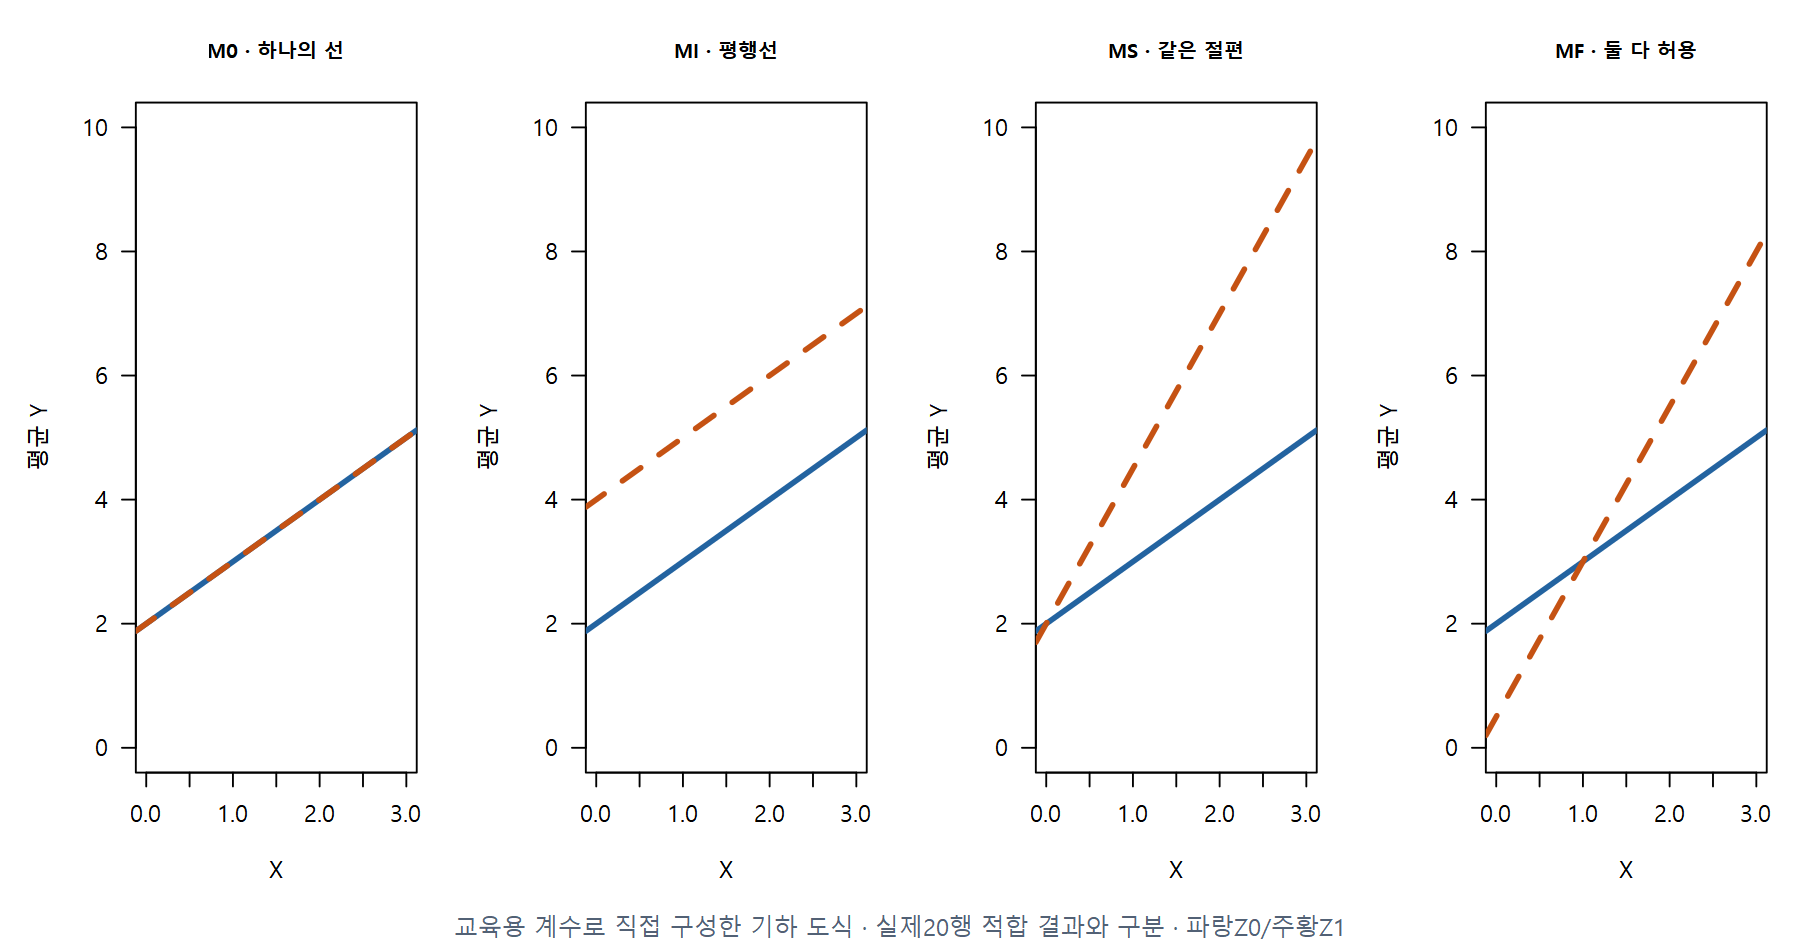

In [ ]:
cat_two_group_models <- function(data) {
  columns <- c("TEST","RACE","JPERF")
  if (!is.data.frame(data) || !all(columns %in% names(data)) || nrow(data)<6L ||
      !all(vapply(data[columns],is.numeric,logical(1))) ||
      any(!is.finite(as.matrix(data[columns]))) ||
      any(!data$RACE %in% 0:1) || length(unique(data$RACE))!=2L)
    stop("Use complete finite TEST/RACE/JPERF rows with both original 0/1 groups.")
  models <- list(M0=lm(JPERF~TEST,data,na.action=na.fail),
    MI=lm(JPERF~TEST+RACE,data,na.action=na.fail),
    MS=lm(JPERF~TEST+TEST:RACE,data,na.action=na.fail),
    MF=lm(JPERF~TEST*RACE,data,na.action=na.fail))
  invisible(lapply(models,cat_check_fit))
  models
}
mods <- cat_two_group_models(pre)
print(model.matrix(mods$MF)[1:6,])
print(coef(mods$MF))

## Z 대입과 두 직선·집단 차이

cat_group_lines는 없는 항을 명시적인0 제약으로 읽습니다. cat_gap은 집단1−집단0=절편 차이+기울기 차이×X를 계산합니다. 기준점 X=0의 의미와 지지 범위를 확인합니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f12.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f12.png)

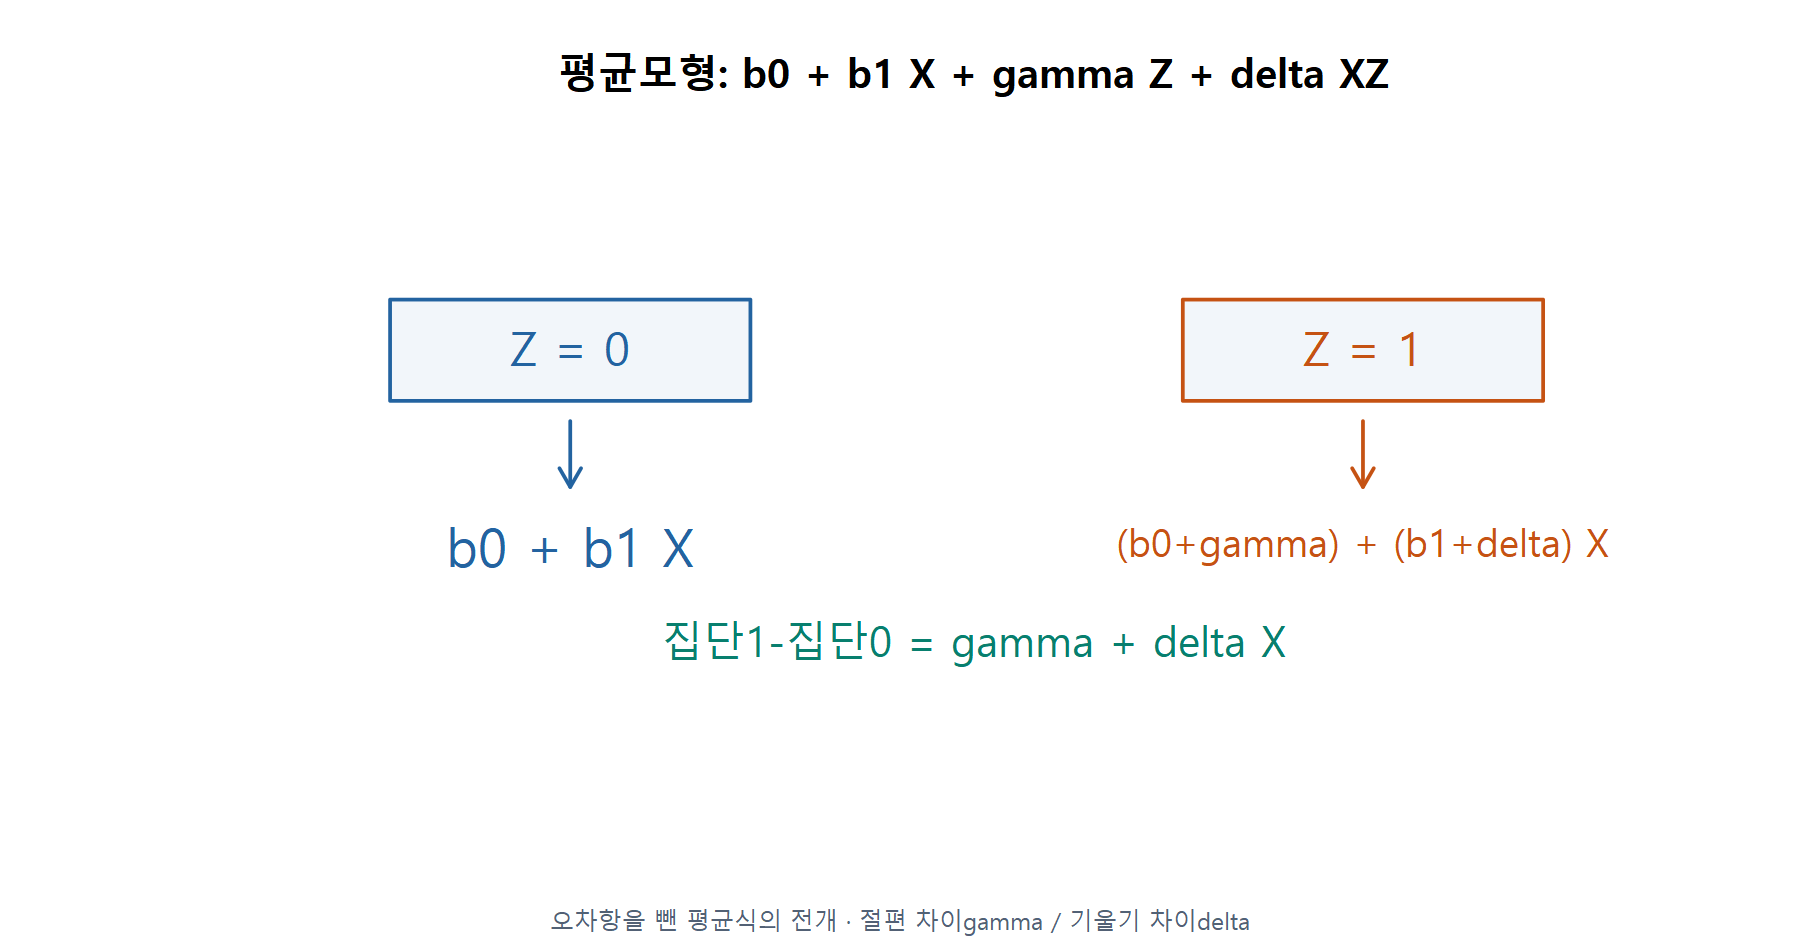

In [ ]:
cat_group_lines <- function(fit) {
  cat_check_fit(fit)
  beta <- c("(Intercept)"=0,"TEST"=0,"RACE"=0,"TEST:RACE"=0)
  if (!all(names(coef(fit)) %in% names(beta)))
    stop("Use a TEST/RACE model from this two-group comparison.")
  beta[names(coef(fit))] <- coef(fit)
  Z <- 0:1
  data.frame(Z=Z,intercept=unname(beta["(Intercept)"]+beta["RACE"]*Z),
    slope=unname(beta["TEST"]+beta["TEST:RACE"]*Z))
}
cat_gap <- function(gamma, delta, x) {
  if (length(gamma)!=1L || length(delta)!=1L || !is.numeric(gamma) ||
      !is.numeric(delta) || !is.numeric(x) || !length(x) ||
      any(!is.finite(c(gamma,delta,x)))) stop("Use finite scalar gaps and finite x.")
  gamma+delta*x
}
lines_full <- cat_group_lines(mods$MF)
print(lines_full,digits=6)
new_two <- data.frame(TEST=1.5,RACE=0:1)
print(cbind(new_two,prediction=predict(mods$MF,new_two)))
print(cat_gap(diff(lines_full$intercept),diff(lines_full$slope),c(.5,1.5,2.3)))
plot(pre$TEST,pre$JPERF,col=ifelse(pre$RACE==0,"steelblue","darkorange"),pch=19,xlab="TEST",ylab="JPERF")
for(i in 1:2) abline(lines_full$intercept[i],lines_full$slope[i],col=c("steelblue","darkorange")[i],lwd=2)

## E06-1 · 전체20행의 잔차 제곱합

두 모형에서 같은20개 반응값을 사용합니다. 아래 실제 정의에서 QR→예측→잔차→제곱→합을 찾고 첫4행의 제곱을 손으로 확인하세요. SSE는20행 전부의 합입니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f14.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f14.png)

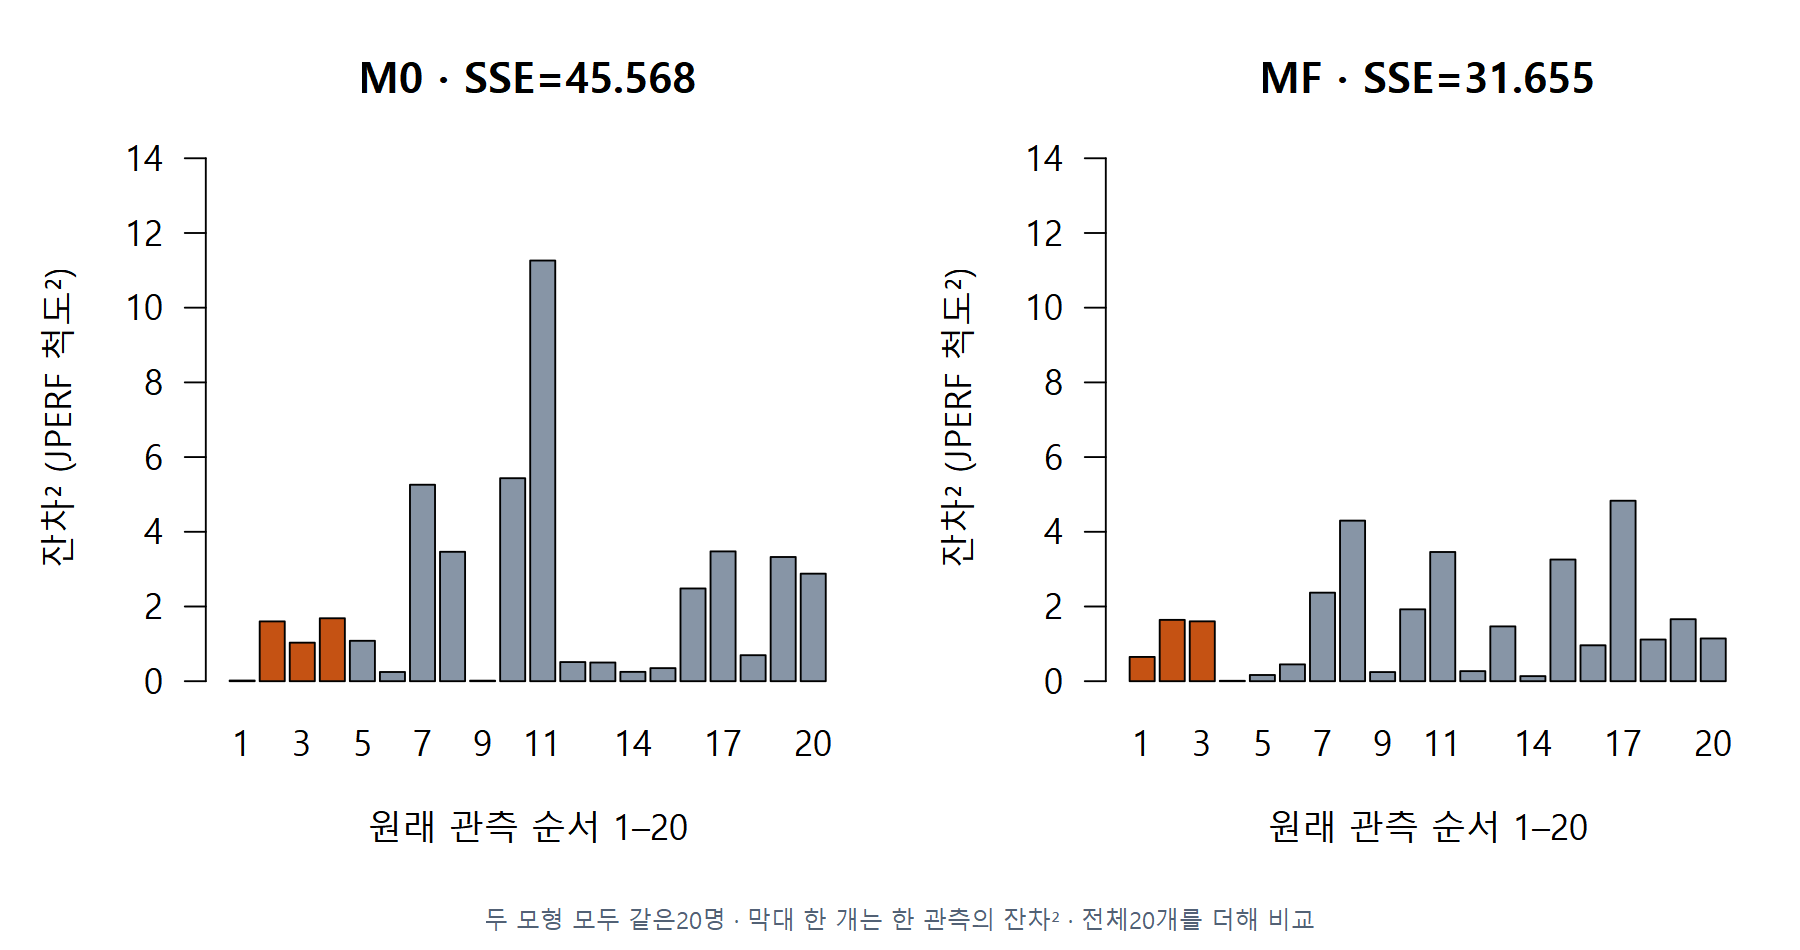

In [ ]:
cat_fit_trace <- function(fit) {
  frame <- cat_check_fit(fit)
  design <- model.matrix(fit)
  observed <- model.response(frame)
  beta <- qr.coef(qr(design),observed)
  fitted <- drop(design %*% beta)
  residual <- observed-fitted
  squared <- residual^2
  rows <- data.frame(source_row=rownames(design),observed=unname(observed),
    fitted=unname(fitted),residual=unname(residual),squared=unname(squared),
    cumulative=cumsum(unname(squared)),row.names=NULL)
  list(design=design,coefficients=beta,rows=rows,
    SSE=sum(squared),n=nrow(design),k=ncol(design),df=df.residual(fit))
}
trace0 <- cat_fit_trace(mods$M0);traceF <- cat_fit_trace(mods$MF)
print(trace0$rows[1:4,],digits=6);print(traceF$rows[1:4,],digits=6)
print(c(SSE0=trace0$SSE,SSEF=traceF$SSE,dfF=traceF$df))

## E06-2 · 부분 F의 실제 구현

cat_check_pair는 같은 행ID·같은 반응값·중첩을 검사합니다. 그 다음 아래 정의가 두 SSE, 추가 계수 수q, 완전모형df, F와 상측 확률p를 계산합니다. 검사 함수의 전체 정의도 뒤의 입력 검사 부록에 있습니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f15.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f15.png)

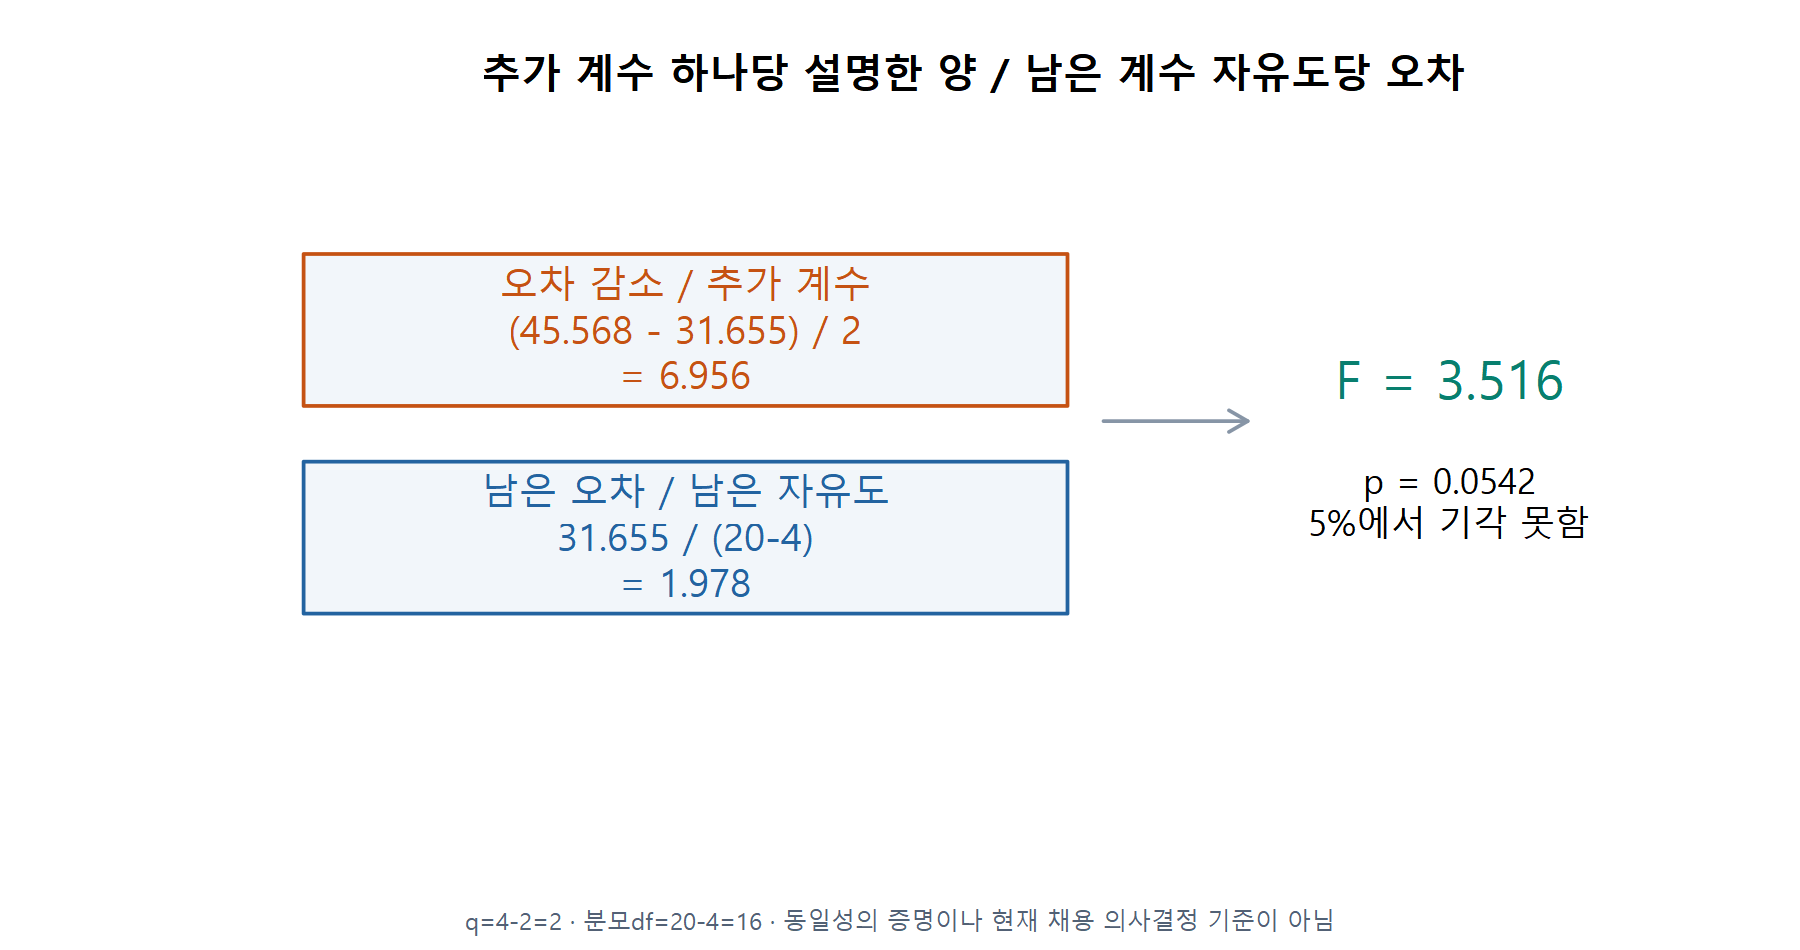

In [ ]:
cat_nested_trace <- function(reduced, full, tolerance=1e-9) {
  checked <- cat_check_pair(reduced,full,tolerance)
  SSE_reduced <- sum(residuals(reduced)^2)
  SSE_full <- sum(residuals(full)^2)
  if (SSE_full<=0 ||
      SSE_reduced<SSE_full-tolerance*max(1,SSE_reduced))
    stop("F needs positive full-model residual variance and a valid nested SSE.")
  q <- checked$q
  df_full <- checked$df_full
  # A tiny negative difference can only be numerical roundoff for nested OLS.
  increase <- max(0,SSE_reduced-SSE_full)
  F <- (increase/q)/(SSE_full/df_full)
  data.frame(n=checked$n,k_reduced=reduced$rank,k_full=full$rank,q=q,
    df_full=df_full,SSE_reduced=SSE_reduced,SSE_full=SSE_full,
    F=F,p=pf(F,q,df_full,lower.tail=FALSE))
}
comparison <- cat_nested_trace(mods$M0,mods$MF)
print(comparison,digits=9)
print(anova(mods$M0,mods$MF))

## E07 · 세 제약과 서로 다른 비교

모든 비교에서 같은20행을 유지하지만 완전모형이 달라지면 분모 자유도도 바뀝니다. MI와MS끼리는 중첩 비교가 아닙니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f16.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f16.png)

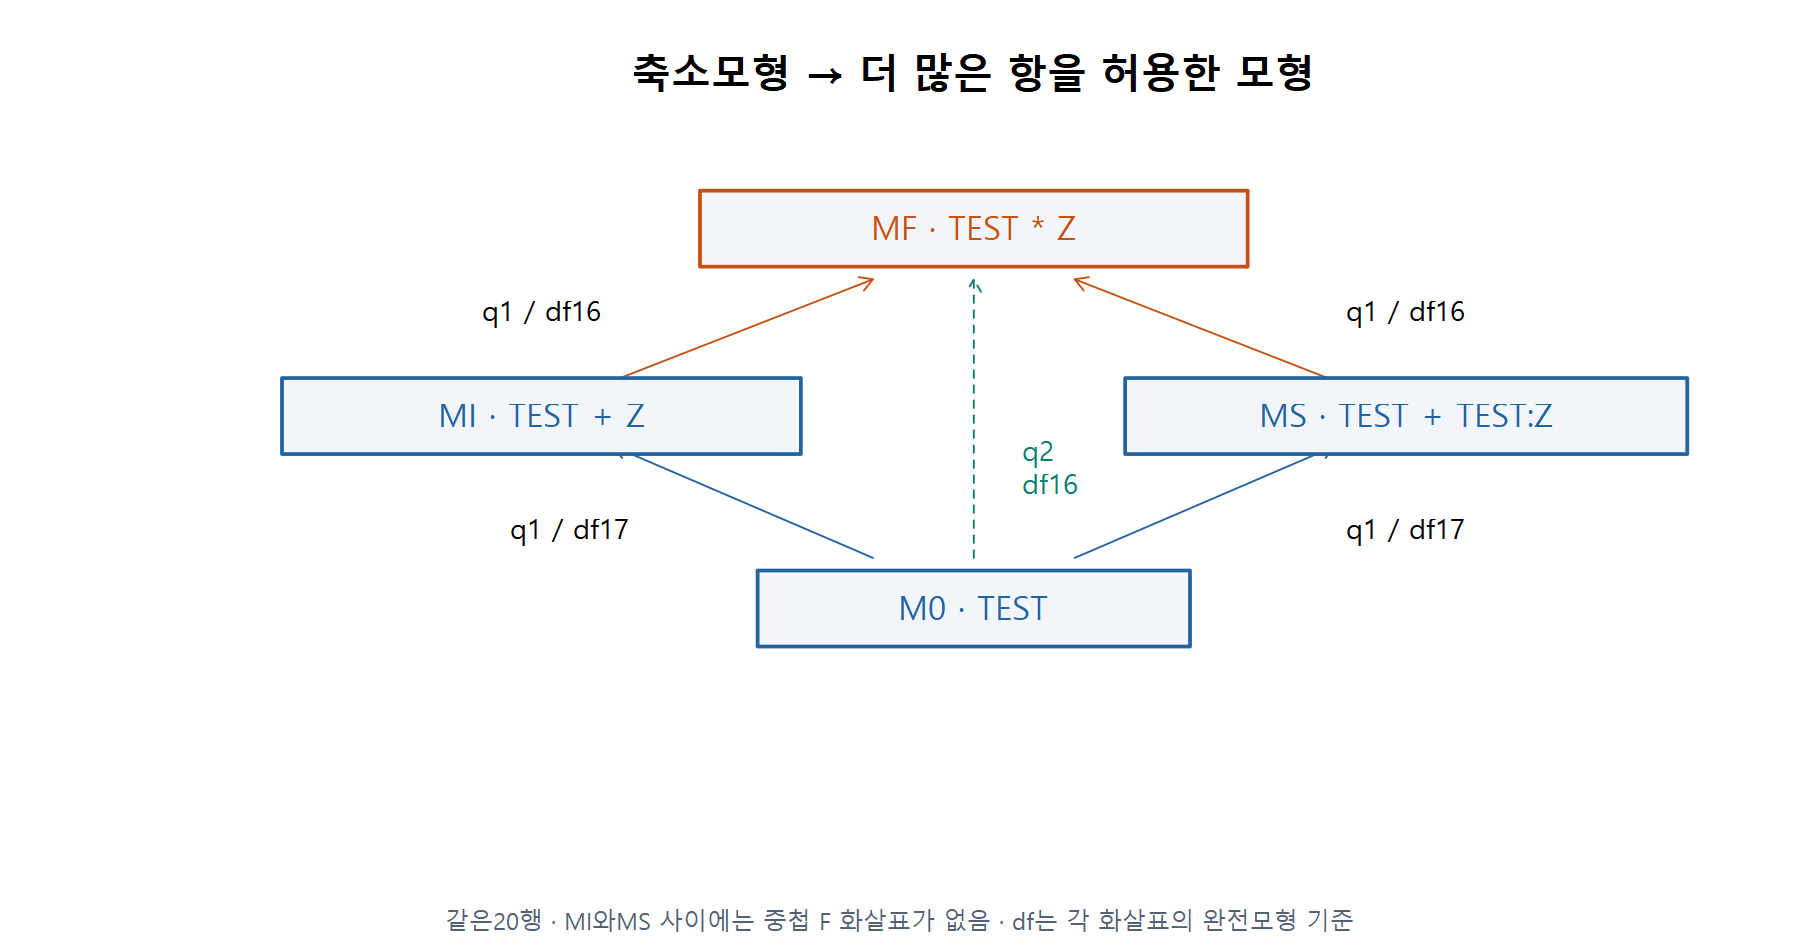

In [ ]:
comparison_pairs <- list(c("M0","MF"),c("M0","MI"),c("M0","MS"),c("MI","MF"),c("MS","MF"))
comparison_table <- do.call(rbind,lapply(comparison_pairs,function(pair) cbind(reduced=pair[1],full=pair[2],cat_nested_trace(mods[[pair[1]]],mods[[pair[2]]]))))
print(comparison_table,digits=7)

## E08 · 평균 회귀선을 거꾸로 읽기

집단1의 별도 회귀선에서 고정된 평균 반응4에 대응하는 TEST를 읽습니다. 점추정은 개인의 실제 결과 보장이 아니며, 아래는 X구간을 계산하는 코드가 아닙니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f17.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f17.png)

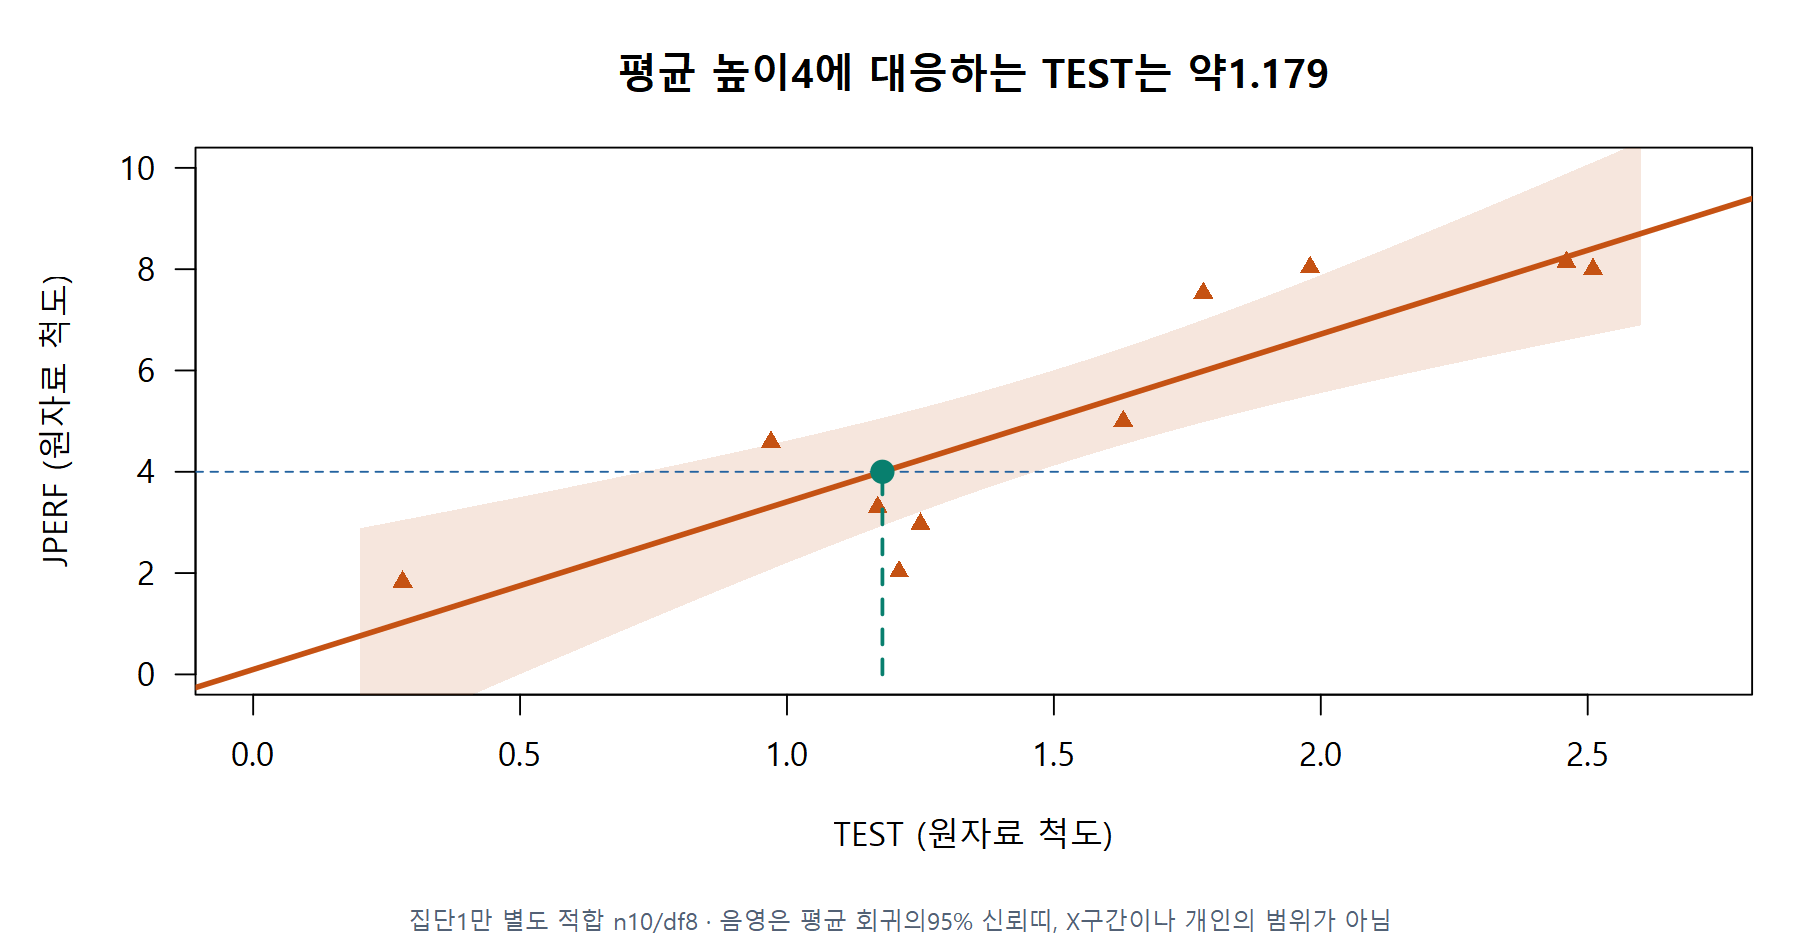

In [ ]:
group1 <- lm(JPERF~TEST,pre[pre$RACE==1,])
beta1 <- coef(group1)
x_at_mean4 <- unname((4-beta1[1])/beta1[2])
print(c(TEST_point_estimate=x_at_mean4,n=nobs(group1),df=df.residual(group1)))

## L06 연결 · 직접 수정하는 모형 함수

이 함수는 앱의 student_formula와 같은 초기 정의입니다. *를 +로 바꾼 사본에서 어떤 열과 기울기 차이가 사라질지 먼저 적으세요. 이 셀의 edited_model은 실제 수정된 함수를 호출하므로 표와 검정이 함께 바뀝니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f18.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f18.png)

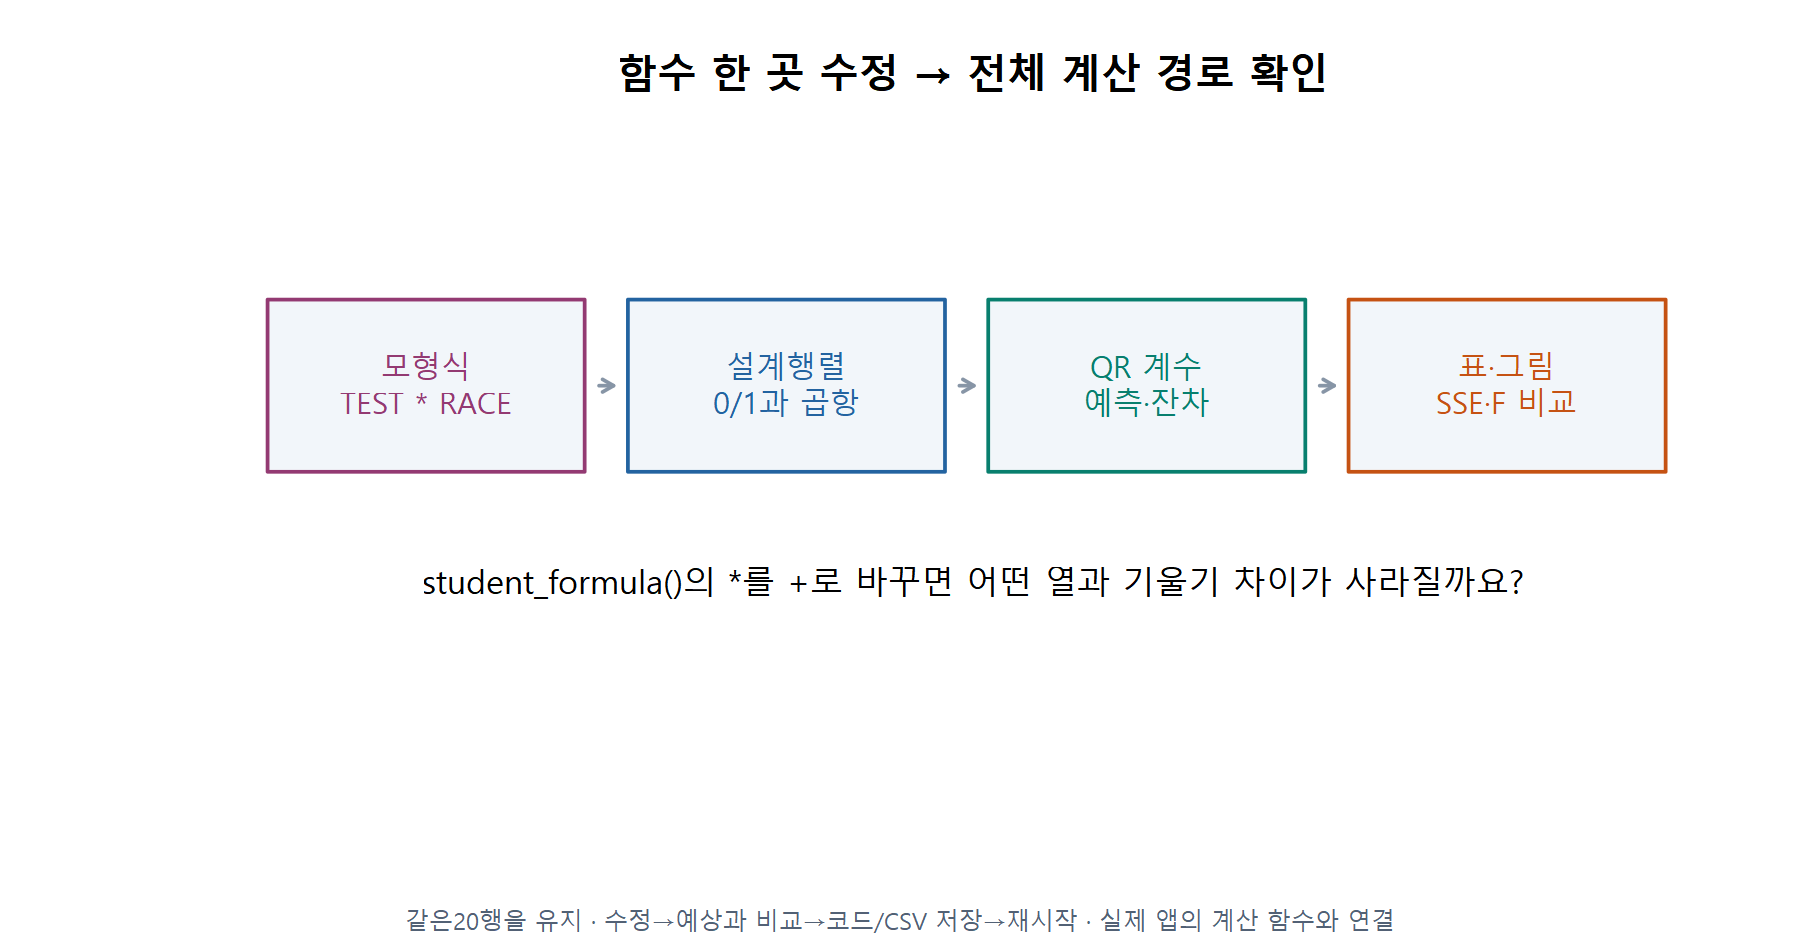

In [ ]:
student_formula <- function() JPERF ~ TEST * RACE
edited_model <- lm(student_formula(),pre)
print(model.matrix(edited_model)[1:4,])
print(cat_group_lines(edited_model))
print(cat_nested_trace(mods$M0,edited_model))

### L04 · 숫자가 다른 두 집단 식

목표: Z 대입과 차이의 함수

교육용 평균모형 $Y=2+X-Z+2XZ$에서 Z=0/1의 두 선을 쓰세요. X=2에서 각각의 평균과 집단1−0의 차이를 구하세요. X=3에서는 차이가 어떻게 되나요?

힌트: 먼저 Z=0을 식 전체에 대입하고 다음에 Z=1을 넣습니다.

자가 점검: 집단 차이가 절편 차이+기울기 차이×X인지 확인합니다.

In [ ]:
my_L04_prediction <- NA_real_
my_L04_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L05 · 부분 F의 분자와 분모

목표: 동일 행·중첩·자유도

같은 20명에서 M0의 SSE는 45.568297, MF는 31.655473입니다. 두 모형의 계수 수, q, 분모 자유도, F를 직접 계산한 뒤 R과 비교하세요. M0→MI의 분모도 16인지 설명하세요.

힌트: 완전모형마다 계수 수가 다릅니다. gamma와 delta를 모두 더하는 경우부터 봅니다.

자가 점검: 수계산 F와 anova의 F가 반올림 범위에서 같아야 합니다.

In [ ]:
my_L05_prediction <- NA_real_
my_L05_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L06 · 모형 함수를 바꾸어 앱까지 연결

목표: 평균모형 제약의 실제 구현

앱 편집기에서 student_formula()의 TEST * RACE를 TEST + RACE로 바꾼 사본을 실행하세요. 바꾸기 전에 사라질 열과 두 기울기의 관계를 예상하세요. 표·그림·SSE/F를 비교하고 수정 R/CSV를 저장한 뒤 재시작하세요.

힌트: R 공식에서 *는 주효과와 곱항을 함께, +는 주효과만 넣습니다. 원본을 보존하세요.

자가 점검: 두 기울기가 같아지는지, 행 수는 20인지, 제목뿐 아니라 계산 결과도 바뀌었는지 확인합니다.

In [ ]:
my_L06_prediction <- NA_real_
my_L06_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L09 · 같은 절편과 중심화

목표: 제약을 두는 위치

교육용 두 선 $Y_0=2+X$와 $Y_1=2+3X$는 X=0에서 같습니다. $X_c=X-1$로 바꾸어 두 식을 쓰세요. 새 절편이 같나요? Xc의 집단 항을 생략하는 것이 원래 제약과 같나요?

힌트: X=Xc+1을 두 식에 대입합니다.

자가 점검: 원래 X=0은 새 좌표의 어디인지 확인합니다.

In [ ]:
my_L09_prediction <- NA_real_
my_L09_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L10 · 검정 결과를 한 문장으로

목표: 비기각과 동일성 구별

전체 비교 p=.054236일 때 미리 정한 5% 기준의 결론을 쓰세요. 한 집단의 기울기만 유의하다는 사실로 두 기울기 차이를 판정할 수 있는지도 설명하세요.

힌트: 비기각은 동일성의 증명이 아닙니다. 비교하려는 차이 자체의 검정이 필요합니다.

자가 점검: 표본·모형·유의수준·불확실성을 포함한 문장인지 읽습니다.

In [ ]:
my_L10_prediction <- NA_real_
my_L10_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

## 입력 검사 부록

같은 행·반응값·중첩·완전계수 조건을 검사하는 실제 정의입니다. 별도 API 페이지를 열지 않고도 읽을 수 있습니다.

In [ ]:
cat_check_fit <- function(fit) {
  if (!inherits(fit,"lm") || !is.data.frame(fit$model))
    stop("Use a standard lm with its complete model frame retained.")
  frame <- fit$model
  design <- model.matrix(fit)
  y <- model.response(frame)
  if (!is.numeric(y) || is.matrix(y) || any(!is.finite(y)) ||
      any(!is.finite(design)) || !is.null(model.weights(frame)) ||
      !is.null(model.offset(frame)) || fit$rank!=ncol(design) ||
      df.residual(fit)<1L || any(!is.finite(coef(fit))))
    stop("Require finite, unweighted, no-offset, full-rank univariate OLS with residual df.")
  frame
}

In [ ]:
cat_check_pair <- function(reduced, full, tolerance=1e-9) {
  r <- cat_check_fit(reduced)
  f <- cat_check_fit(full)
  if (!identical(rownames(r),rownames(f)) ||
      !isTRUE(all.equal(model.response(r),model.response(f),tolerance=0)))
    stop("Compare the same response and identical observations in identical order.")
  xr <- model.matrix(reduced)
  xf <- model.matrix(full)
  if (length(tolerance)!=1L || !is.numeric(tolerance) ||
      !is.finite(tolerance) || tolerance<=0) stop("Use positive finite tolerance.")
  q <- full$rank-reduced$rank
  if (q<=0 || max(abs(qr.resid(qr(xf),xr)))>tolerance*max(1,abs(xr)))
    stop("Reduced design must be nested in full design with fewer parameters.")
  list(n=nrow(f),q=q,df_full=df.residual(full))
}

In [ ]:
stopifnot(nrow(pre)==20,mods$MF$rank==4,comparison$q==2,comparison$df_full==16,
 abs(comparison$F-anova(mods$M0,mods$MF)$F[2])<1e-9,
 abs(comparison$p-.054236056264714)<1e-10,
 cat_nested_trace(mods$M0,mods$MI)$df_full==17,
 cat_nested_trace(mods$M0,mods$MS)$df_full==17)
cat("W11A_GROUPS_RUNTIME_PASS: source calculations, not exercise completion\n")